# **Environment Setup and Dataset Acquisition**
This cell initializes the working environment by installing necessary dependencies (SoccerNet toolkit and Ultralytics) and mounting Google Drive. It subsequently downloads the **SoccerNet** Tracking 2023 dataset (specifically the Train and Test splits) into the specified directory to ensure all raw data is available for processing.

In [ ]:
import os
import subprocess
from google.colab import drive

def setup_environment():
    """
    Installs necessary Python packages (SoccerNet, Ultralytics) and mounts Google Drive.
    """
    print("Installing dependencies...")
    subprocess.check_call(['pip', 'install', '-q', 'SoccerNet', 'ultralytics'])

    print("Mounting Google Drive...")
    drive.mount('/content/drive')

def download_data(local_directory):
    """
    Downloads the 'tracking-2023' dataset (train, test).
    """
    from SoccerNet.Downloader import SoccerNetDownloader

    print(f"Initializing download to: {local_directory}")
    mySoccerNetDownloader = SoccerNetDownloader(LocalDirectory=local_directory)

    # Download all necessary splits:
    # - train: for training weights
    # - test: half for validation during training and half as a test set during the inference
    mySoccerNetDownloader.downloadDataTask(task="tracking-2023", split=["train", "test"])


# --- Main Execution ---

# Define persistent storage path (User specific)
DATA_DIR = "/content/drive/MyDrive/ArtificialVision_Project_G23"

# 1. Setup
setup_environment()

# 2. Download Data
# Checks are handled internally by the library (it won't re-download if files exist)
download_data(DATA_DIR)

# 3. Analyze Structures
# We verify that we have the raw data for all 3 splits
base_tracking_path = os.path.join(DATA_DIR, "tracking-2023")

# **Dataset Extraction and Train-Validation-Test Split**
This cell handles the extraction of raw tracking data from compressed archives to a local temporary directory. Crucially, it implements a data partitioning strategy on the original test set: the first 30 sequences are isolated into a Validation Set (for model tuning and optimization), while the remaining 19 sequences constitute the Final Test Set (for official evaluation).

In [ ]:
# --- 1. CONFIGURATION & HYPERPARAMETERS ---

# Source directory on Google Drive containing the zip files
DRIVE_BASE_DIR = "/content/drive/MyDrive/ArtificialVision_Project_G23/tracking-2023"

# Destination directory for extraction (Temporary Colab storage)
LOCAL_EXTRACT_DIR = "/content/temp_data_raw"

# Configuration for the Split
VALIDATION_SIZE = 30  # First 30 sequences go to validation

# --- 2. HELPER FUNCTIONS ---

import os
import zipfile
import shutil

def clean_start():
    """Removes the temp directory to ensure a fresh start."""
    if os.path.exists(LOCAL_EXTRACT_DIR):
        print(f"[Info] Cleaning previous data at {LOCAL_EXTRACT_DIR}...")
        shutil.rmtree(LOCAL_EXTRACT_DIR)
    os.makedirs(LOCAL_EXTRACT_DIR, exist_ok=True)

def extract_zip_flat(zip_filename, source_dir, extract_root):
    """
    Extracts a zip file directly into the extract_root.
    Since SoccerNet zips contain a root folder (e.g., 'train/' or 'test/'),
    this avoids creating double nesting like 'train/train/'.
    """
    source_path = os.path.join(source_dir, zip_filename)

    if not os.path.exists(source_path):
        print(f"[Error] Zip file not found: {source_path}")
        return False

    print(f"[Info] Extracting {zip_filename}...")
    try:
        with zipfile.ZipFile(source_path, 'r') as zip_ref:
            zip_ref.extractall(extract_root)
        return True
    except Exception as e:
        print(f"[Error] Failed to extract {zip_filename}: {e}")
        return False

def prepare_datasets():
    print("--- Starting Dataset Preparation ---\n")

    # 0. Clean workspace
    clean_start()

    # --- 1. PROCESS TRAINING DATA ---
    # train.zip contains a folder named 'train'.
    # Extracting to LOCAL_EXTRACT_DIR results in: LOCAL_EXTRACT_DIR/train
    if extract_zip_flat("train.zip", DRIVE_BASE_DIR, LOCAL_EXTRACT_DIR):
        print("[Success] Training data ready.")

    # --- 2. PROCESS TEST/VALIDATION DATA ---
    # test.zip contains a folder named 'test'.
    # Extracting to LOCAL_EXTRACT_DIR results in: LOCAL_EXTRACT_DIR/test
    # BUT we need to split this. To avoid conflicts, we will rename it immediately.

    if extract_zip_flat("test.zip", DRIVE_BASE_DIR, LOCAL_EXTRACT_DIR):

        # Path created by the zip
        extracted_test_path = os.path.join(LOCAL_EXTRACT_DIR, "test")

        # Temporary path to hold these files before splitting
        source_split_path = os.path.join(LOCAL_EXTRACT_DIR, "source_to_split")

        # Rename 'test' -> 'source_to_split' to avoid confusion with the final 'test' folder
        if os.path.exists(extracted_test_path):
            shutil.move(extracted_test_path, source_split_path)

        # Now create the final folders
        val_path = os.path.join(LOCAL_EXTRACT_DIR, "validation")
        final_test_path = os.path.join(LOCAL_EXTRACT_DIR, "test")

        os.makedirs(val_path, exist_ok=True)
        os.makedirs(final_test_path, exist_ok=True)

        # Perform Split
        print(f"\n--- Splitting Test Source (First {VALIDATION_SIZE} -> Validation) ---")

        # Get all sequence folders (SNMOT-XXX)
        sequences = sorted([d for d in os.listdir(source_split_path) if d.startswith("SNMOT")])

        val_seqs = sequences[:VALIDATION_SIZE]
        test_seqs = sequences[VALIDATION_SIZE:]

        print(f" -> Moving {len(val_seqs)} sequences to {val_path}")
        for seq in val_seqs:
            shutil.move(os.path.join(source_split_path, seq), os.path.join(val_path, seq))

        print(f" -> Moving {len(test_seqs)} sequences to {final_test_path}")
        for seq in test_seqs:
            shutil.move(os.path.join(source_split_path, seq), os.path.join(final_test_path, seq))

        # Cleanup the temporary source folder
        os.rmdir(source_split_path)
        print("[Success] Split completed.")

    # --- 3. FINAL VERIFICATION ---
    print(f"\n--- Final Structure at {LOCAL_EXTRACT_DIR} ---")
    for folder in ['train', 'validation', 'test']:
        p = os.path.join(LOCAL_EXTRACT_DIR, folder)
        if os.path.exists(p):
            count = len([d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d))])
            print(f"[{folder}] contains {count} sequences.")
        else:
            print(f"[{folder}] MISSING!")

# Run the process
if __name__ == "__main__":
    prepare_datasets()

# **YOLO Dataset Conversion with Label Filtering**
This cell transforms the raw SoccerNet tracking data into the **standard Ultralytics YOLO format** (compatible with YOLOv8/YOLO11). It performs three operations:

**Label Filtering:** Parses the gameinfo.ini metadata to map tracking IDs to semantic labels, strictly filtering for human classes (players, referees, goalkeepers) and automatically excluding the ball to prevent false positives.

**Coordinate Normalization:** Converts bounding boxes from absolute coordinates [x, y, w, h] to YOLO's normalized format [x_center, y_center, width, height].

**Data Sampling:** Applies a temporal stride (processing 1 frame every 5) to reduce dataset redundancy and training time while maintaining representative diversity.

In [ ]:
# --- 1. CONFIGURATION & HYPERPARAMETERS ---

# Source directories (created in the previous Split step)
TRAIN_SOURCE_DIR = "/content/temp_data_raw/train"
VAL_SOURCE_DIR = "/content/temp_data_raw/validation"

# Output directory for the YOLO-formatted dataset
YOLO_OUTPUT_DIR = "/content/soccernet_yolo"

# Sampling Stride
SAMPLING_STRIDE = {
    "train": 5,
    "val": 5
}

# Image extension
EXPECTED_IMG_EXT = ".jpg"

# --- 2. CLASS MAPPING ---

# Strict mapping based on the provided list.
# Anything else (including 'ball') will be mapped to NaN and dropped.
LABEL_MAP = {
    'player team left': 0,
    'player team right': 0,
    'goalkeepers team left': 0,
    'goalkeeper team left': 0,
    'goalkeepers team right': 0,
    'goalkeeper team right': 0,
    'referee': 0
}

# --- 3. HELPER FUNCTIONS ---

import os
import cv2
import pandas as pd
import glob
import shutil
import yaml
from tqdm import tqdm

def get_yolo_bbox(img_w, img_h, box):
    """Converts MOT [x, y, w, h] to YOLO [x_c, y_c, w_n, h_n]."""
    x, y, w, h = box

    # Clip to image boundaries
    x = max(0, x)
    y = max(0, y)
    w = min(w, img_w - x)
    h = min(h, img_h - y)

    # Normalize
    x_c = (x + w / 2) / img_w
    y_c = (y + h / 2) / img_h
    w_n = w / img_w
    h_n = h / img_h

    return [x_c, y_c, w_n, h_n]

def parse_gameinfo(ini_path):
    """
    Parses gameinfo.ini to map TrackID -> Label Name.
    Ex: trackletID_1= player team left;4  -->  {1: 'player team left'}
    """
    mapping = {}
    if not os.path.exists(ini_path):
        return mapping

    try:
        with open(ini_path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                line = line.strip()
                if line.startswith("trackletID_"):
                    # split key and value
                    parts = line.split('=')
                    if len(parts) == 2:
                        key_part = parts[0].strip() # trackletID_1
                        # Take the part before the semicolon
                        val_part = parts[1].split(';')[0].strip() # player team left

                        try:
                            t_id = int(key_part.replace("trackletID_", ""))
                            mapping[t_id] = val_part
                        except ValueError:
                            continue
    except Exception:
        pass

    return mapping

# --- 4. DATASET GENERATION LOGIC ---

def process_dataset_split(source_dir, split_name, output_root, stride):
    """
    Converts a dataset split (train/val) to YOLO format using gameinfo.ini labels.
    """
    print(f"\n--- Processing Split: {split_name} ---")

    # Define YOLO directories
    img_dest_dir = os.path.join(output_root, 'images', split_name)
    lbl_dest_dir = os.path.join(output_root, 'labels', split_name)
    os.makedirs(img_dest_dir, exist_ok=True)
    os.makedirs(lbl_dest_dir, exist_ok=True)

    # Get sequences (numeric folders or SNMOT-)
    all_items = os.listdir(source_dir)
    sequences = []
    for d in all_items:
        full_p = os.path.join(source_dir, d)
        if os.path.isdir(full_p):
            if d.isdigit() or d.startswith("SNMOT-"):
                sequences.append(d)

    sequences = sorted(sequences)

    if not sequences:
        print(f"[Warning] No sequences found in {source_dir}")
        return

    frames_processed = 0

    for seq in tqdm(sequences, desc=f"Converting {split_name}"):
        seq_path = os.path.join(source_dir, seq)

        ini_file = os.path.join(seq_path, 'gameinfo.ini')
        gt_file = os.path.join(seq_path, 'gt', 'gt.txt')
        img_dir = os.path.join(seq_path, 'img1')

        if not os.path.exists(gt_file) or not os.path.exists(img_dir):
            continue

        # 1. Get ID -> Label mapping from INI
        id_map = parse_gameinfo(ini_file)
        if not id_map:
            # Fallback or Skip? Usually skip if strict filtering is needed.
            continue

        # 2. Load GT
        try:
            df = pd.read_csv(gt_file, header=None)
            # Use only first 6 columns: frame, id, x, y, w, h
            df = df.iloc[:, :6]
            df.columns = ['frame', 'track_id', 'x', 'y', 'w', 'h']
        except Exception:
            continue

        # 3. Apply Filters
        # Map Track ID to Label String (e.g. 1 -> "player team left")
        df['label_str'] = df['track_id'].map(id_map)

        # Map Label String to Class ID (0) using the strict dictionary
        # 'ball' is not in LABEL_MAP, so it becomes NaN
        df['class_id'] = df['label_str'].map(LABEL_MAP)

        # Remove NaNs (balls, etc.)
        df_clean = df.dropna(subset=['class_id']).copy()

        # 4. Generate Files
        for frame_id, group in df_clean.groupby('frame'):

            # Stride check
            if (frame_id - 1) % stride != 0:
                continue

            frame_filename = f"{int(frame_id):06d}{EXPECTED_IMG_EXT}"
            src_img_path = os.path.join(img_dir, frame_filename)

            if not os.path.exists(src_img_path):
                continue

            # Define output paths
            unique_name = f"{seq}_{int(frame_id):06d}"
            dst_img_path = os.path.join(img_dest_dir, unique_name + EXPECTED_IMG_EXT)
            dst_lbl_path = os.path.join(lbl_dest_dir, unique_name + ".txt")

            # Copy Image
            shutil.copy(src_img_path, dst_img_path)

            # Read Image Dims (from destination to be sure)
            img = cv2.imread(dst_img_path)
            if img is None: continue
            h, w = img.shape[:2]

            # Write Labels
            with open(dst_lbl_path, 'w') as f_out:
                for _, row in group.iterrows():
                    cls = int(row['class_id']) # 0
                    box = [row['x'], row['y'], row['w'], row['h']]

                    yolo_box = get_yolo_bbox(w, h, box)

                    line = f"{cls} {yolo_box[0]:.6f} {yolo_box[1]:.6f} {yolo_box[2]:.6f} {yolo_box[3]:.6f}\n"
                    f_out.write(line)

            frames_processed += 1

    print(f"[Info] {split_name}: {frames_processed} frames generated.")

def create_yaml_config(output_dir):
    data = {
        'path': os.path.abspath(output_dir),
        'train': 'images/train',
        'val': 'images/val',
        'names': {0: 'person'}
    }

    yaml_path = os.path.join(output_dir, 'data.yaml')
    with open(yaml_path, 'w') as f:
        yaml.dump(data, f, sort_keys=False)

    print(f"[Info] Config saved: {yaml_path}")
    return yaml_path

# --- 5. EXECUTION ---

if __name__ == "__main__":
    # Clean previous run
    if os.path.exists(YOLO_OUTPUT_DIR):
        shutil.rmtree(YOLO_OUTPUT_DIR)

    # Process Train
    process_dataset_split(TRAIN_SOURCE_DIR, "train", YOLO_OUTPUT_DIR, SAMPLING_STRIDE["train"])

    # Process Validation (Mapped to 'val' folder for YOLO)
    process_dataset_split(VAL_SOURCE_DIR, "val", YOLO_OUTPUT_DIR, SAMPLING_STRIDE["val"])

    # Create YAML
    create_yaml_config(YOLO_OUTPUT_DIR)

# **YOLO Model Fine-Tuning and Training Pipeline**
This cell configures and executes the supervised fine-tuning of the **YOLO11l** (Large) model on the prepared SoccerNet dataset. It defines the training hyperparameters—specifically optimized for small object detection via a high input resolution (imgsz=1920, the native frame resolution)—and initiates the training loop using the Ultralytics engine. Post-training, the pipeline generates a comprehensive performance dashboard to monitor Loss and mAP metrics and automatically backs up the best model weights and logs to Google Drive to ensure persistence across Colab sessions.

In [ ]:
# --- 1. CONFIGURATION & HYPERPARAMETERS ---

# Model Selection: YOLO11 Large (Best balance for accuracy on small objects)
MODEL_WEIGHTS = 'yolo11l.pt'
PROJECT_NAME = "yolo11l_soccer_finetune"

# Training Configuration
HYPERPARAMS = {
    # --- Training Parameters ---
    "epochs": 70,                 # Number of training epochs
    "imgsz": 1920,                # Native resolution (Critical for small players)
    "batch": 8,                   # Reduced batch size to prevent OutOfMemory on GPU
    "patience": 10,               # Early stopping patience
    "device": 0,                  # GPU ID

    # --- Optimizer & Scheduling ---
    "optimizer": "auto",          # Ultralytics smart optimizer selection
    "seed": 42,                   # Reproducibility
    "cos_lr": True,               # Cosine scheduler for better convergence

    # --- Warmup ---
    "warmup_epochs": 3.0,         # Warmup to stabilize gradients at the start
    "warmup_momentum": 0.8,       # Initial momentum during warmup

    # --- System ---
    "plots": True,                # Enable default YOLO plotting
    "workers": 12,                # Maximize data loading speed
    "val": True,                  # Validate during training
    "save": True                  # Save checkpoints
}

# Directories
DATA_YAML_PATH = "/content/soccernet_yolo/data.yaml"
LOCAL_RUNS_DIR = "/content/training_runs"

# Backup Location on Google Drive
DRIVE_BACKUP_DIR = "/content/drive/MyDrive/ArtificialVision_Project_G23/training_results"

# --- 2. HELPER FUNCTIONS ---

import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

def plot_training_metrics_2x2(results_csv_path, save_dir):
    """
    Generates a 2x2 dashboard of training metrics:
    1. Box Loss (Localization)
    2. Class Loss (Identification)
    3. DFL Loss (Boundary Precision)
    4. mAP Score (Overall Performance)
    """
    if not os.path.exists(results_csv_path):
        print(f"[Warning] Results file missing at {results_csv_path}. Cannot plot.")
        return

    try:
        # Read CSV and strip whitespace from column names
        df = pd.read_csv(results_csv_path)
        df.columns = df.columns.str.strip()
    except Exception as e:
        print(f"[Error] Failed to parse CSV: {e}")
        return

    # Setup 2x2 Figure
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    epochs = df['epoch']

    # --- Plot 1: Box Loss ---
    ax = axes[0, 0]
    if 'train/box_loss' in df.columns and 'val/box_loss' in df.columns:
        ax.plot(epochs, df['train/box_loss'], label='Train', marker='.', color='tab:blue')
        ax.plot(epochs, df['val/box_loss'], label='Validation', marker='.', color='tab:orange')
        ax.set_title('Box Loss (IoU Accuracy)')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid(True, alpha=0.3)

    # --- Plot 2: Class Loss ---
    ax = axes[0, 1]
    if 'train/cls_loss' in df.columns and 'val/cls_loss' in df.columns:
        ax.plot(epochs, df['train/cls_loss'], label='Train', marker='.', color='tab:blue')
        ax.plot(epochs, df['val/cls_loss'], label='Validation', marker='.', color='tab:orange')
        ax.set_title('Class Loss (Object ID)')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid(True, alpha=0.3)

    # --- Plot 3: DFL Loss ---
    ax = axes[1, 0]
    if 'train/dfl_loss' in df.columns and 'val/dfl_loss' in df.columns:
        ax.plot(epochs, df['train/dfl_loss'], label='Train', marker='.', color='tab:blue')
        ax.plot(epochs, df['val/dfl_loss'], label='Validation', marker='.', color='tab:orange')
        ax.set_title('DFL Loss (Boundary Refinement)')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid(True, alpha=0.3)

    # --- Plot 4: mAP Metrics ---
    ax = axes[1, 1]
    if 'metrics/mAP50(B)' in df.columns and 'metrics/mAP50-95(B)' in df.columns:
        ax.plot(epochs, df['metrics/mAP50(B)'], label='mAP@50 (Detection)', color='tab:green', marker='o')
        ax.plot(epochs, df['metrics/mAP50-95(B)'], label='mAP@50-95 (Precision)', color='tab:red', marker='x')
        ax.set_title('Model Performance (mAP)')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Score (0-1)')
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()

    # Save the dashboard
    plot_path = os.path.join(save_dir, "training_dashboard_2x2.png")
    plt.savefig(plot_path, dpi=150)
    plt.close()

    print(f"[Info] Training dashboard saved to: {plot_path}")

def backup_run_to_drive(local_run_path, drive_root_path, run_name):
    """
    Backs up the entire training run folder to Google Drive.
    """
    destination = os.path.join(drive_root_path, run_name)

    print(f"[Info] Initiating backup to Drive: {destination}")
    os.makedirs(drive_root_path, exist_ok=True)

    try:
        # copytree allows updating existing folders with dirs_exist_ok=True
        shutil.copytree(local_run_path, destination, dirs_exist_ok=True)
        print("[Success] Backup finished successfully.")
        return destination
    except Exception as e:
        print(f"[Error] Backup failed: {e}")
        return None

# --- 3. MAIN TRAINING PIPELINE ---

def run_fine_tuning():
    """
    Main function to execute the training workflow.
    """
    print(f"[Setup] Model: {MODEL_WEIGHTS}")
    print(f"[Setup] Image Size: {HYPERPARAMS['imgsz']}")
    print(f"[Setup] Epochs: {HYPERPARAMS['epochs']}")

    # 1. Load Model
    model = YOLO(MODEL_WEIGHTS)

    # 2. Train
    print("\n--- Starting Training Loop ---")
    results = model.train(
        data=DATA_YAML_PATH,
        project=LOCAL_RUNS_DIR,
        name=PROJECT_NAME,
        **HYPERPARAMS, # Unpack config dictionary
        exist_ok=True,
        pretrained=True,
        verbose=True
    )

    # 3. Post-Training Analysis
    run_path = os.path.join(LOCAL_RUNS_DIR, PROJECT_NAME)
    results_csv = os.path.join(run_path, "results.csv")

    print("\n--- Generating Metrics Dashboard ---")
    plot_training_metrics_2x2(results_csv, run_path)

    # 4. Backup
    print("\n--- Saving Results to Drive ---")
    backup_path = backup_run_to_drive(run_path, DRIVE_BACKUP_DIR, PROJECT_NAME)

    print(f"\n[Complete] Training done. Best weights and plots are in: {backup_path}")
    return model

# --- 4. EXECUTION ---

if __name__ == "__main__":
    trained_model = run_fine_tuning()

# **Environment Setup and Evaluation Utilities**
This cell installs the TrackEval library (official HOTA implementation) by cloning its repository.

The contest evaluator (`evaluation_helper.py`, computing HOTA@0.5 and nMAE in the SoccerNet/MOTChallenge format) was provided by the course staff and is **not included** in this repository. To run the evaluation cells, place `evaluation_helper.py` in the Colab working directory.


In [14]:
# --- 1. SETUP COMMANDS ---
import os
import sys
!pip install lapx>=0.5.5

# Install TrackEval (Required for HOTA metrics)
# We clone the official repo to ensure we have the library available
if not os.path.exists("TrackEval"):
    print("[Setup] Cloning TrackEval repository...")
    !git clone https://github.com/JonathonLuiten/TrackEval.git
    sys.path.append(os.path.abspath("TrackEval"))  # Add to python path

# The contest evaluator 'evaluation_helper.py' was provided by the course staff and is not
# distributed with this repository: copy it into the working directory before running the
# evaluation cells below.
if not os.path.exists("evaluation_helper.py"):
    print("[Setup] WARNING: 'evaluation_helper.py' not found. Evaluation cells will not run.")


# **Dataset Standardization (Evaluation Sets Only)**
This cell standardizes the folder structure for the Validation and Test sets only, renaming sequence directories from SNMOT-XX to numeric format X. This step is strictly required for the evaluation scripts to function correctly. The Training set is skipped in this phase to optimize processing time, as it is not needed for inference or metric calculation.

In [ ]:
# --- 1. CONFIGURATION & VARIABLES ---

# List of dataset roots to standardize.
# We process ONLY 'validation' and 'test' because we are in the evaluation phase.
# We skip 'train' to save time.
DIRS_TO_STANDARDIZE = [
    "/content/temp_data_raw/validation",
    "/content/temp_data_raw/test"
]

# Prefix to look for and remove
TARGET_PREFIX = "SNMOT-"

# --- 2. PRE-PROCESSING FUNCTIONS ---

import os
import shutil

def standardize_dataset_structure(root_path: str, prefix: str) -> None:
    """
    Standardizes the folder names in the dataset directory.
    Renames '{prefix}X' -> 'X'.
    """
    if not os.path.exists(root_path):
        print(f"[Skip] Path not found: {root_path}")
        return

    print(f"\n[Info] Standardizing: {root_path}")

    items = os.listdir(root_path)
    processed_count = 0

    for item in items:
        full_path = os.path.join(root_path, item)

        # Check if folder matches prefix
        if os.path.isdir(full_path) and item.startswith(prefix):
            try:
                # Logic: SNMOT-01 -> 1
                clean_name = item.replace(prefix, "").lstrip("0")
                if clean_name == "": clean_name = "0"

                new_path = os.path.join(root_path, clean_name)

                if not os.path.exists(new_path):
                    os.rename(full_path, new_path)
                    processed_count += 1
                else:
                    # If destination exists (e.g. from a previous run), skip
                    pass

            except Exception as e:
                print(f"[Error] Could not rename '{item}': {e}")

    print(f" -> Renamed {processed_count} folders.")

    # Verification
    final_items = [f for f in os.listdir(root_path) if f.isdigit()]
    print(f" -> Ready sequences: {len(final_items)}")

# --- 3. EXECUTION ---

if __name__ == "__main__":
    for d in DIRS_TO_STANDARDIZE:
        standardize_dataset_structure(d, TARGET_PREFIX)

# **Metadata Generation for Evaluation (ROI & Behavior)**
This cell enriches the Validation and Test datasets by generating the auxiliary metadata files required for the official evaluation scripts. For each video sequence, it creates:

**roi.json:** Defines the spatial boundaries of the two Regions of Interest (ROI) used for behavior analysis.

**behavior_gt.txt:** A computed Ground Truth file for crowd counting. It is generated by projecting the existing tracking annotations onto the ROIs, counting how many objects (ids) are present in each region per frame. This serves as the reference for calculating the nMAE metric.

In [ ]:
# --- 1. CONFIGURATION ---

# List of dataset roots to process
# We need metadata for both Validation (for tuning) and Test (for final verification)
DIRS_TO_PROCESS = [
    "/content/temp_data_raw/validation",
    "/content/temp_data_raw/test"
]

# ROI Configuration
ROI_CONFIG = {
    "roi1": {
        "x": 0.01, "y": 0.01, "width": 0.4, "height": 0.75
    },
    "roi2": {
        "x": 0.5, "y": 0.35, "width": 0.5, "height": 0.5
    }
}

# --- 2. UTILITY FUNCTIONS ---

import os
import json
import glob
import cv2
import pandas as pd
from collections import defaultdict
from tqdm import tqdm

def get_base_center(x, y, w, h):
    """Calculates the bottom-center point of the bounding box (feet position)."""
    return x + (w / 2.0), y + h

def is_point_in_roi(x, y, roi_def, img_w, img_h):
    """Checks if a point lies within the normalized ROI boundaries."""
    rx = roi_def['x'] * img_w
    ry = roi_def['y'] * img_h
    rw = roi_def['width'] * img_w
    rh = roi_def['height'] * img_h
    return (rx <= x <= rx + rw) and (ry <= y <= ry + rh)

def process_single_folder(dataset_root):
    """
    Enriches a dataset folder (e.g., validation) with metadata files.
    """
    if not os.path.exists(dataset_root):
        print(f"[Skip] Directory not found: {dataset_root}")
        return

    print(f"Generating Metadata for: {dataset_root}")

    # Get numeric sequence folders (ensure they are sorted)
    # Note: Folders should already be renamed to '1', '2'... by the previous step
    sequences = sorted([d for d in os.listdir(dataset_root) if d.isdigit()], key=lambda x: int(x))

    if not sequences:
        print(f"[Warning] No numeric folders found in {dataset_root}. Did standardization run?")
        return

    success_count = 0

    for seq_name in tqdm(sequences):
        seq_path = os.path.join(dataset_root, seq_name)

        # 1. Generate ROI.json
        roi_path = os.path.join(seq_path, "roi.json")
        with open(roi_path, "w") as f:
            json.dump(ROI_CONFIG, f, indent=4)

        # 2. Generate Behavior GT
        gt_path = os.path.join(seq_path, "gt", "gt.txt")
        beh_path = os.path.join(seq_path, "gt", "behavior_gt.txt")
        img_dir = os.path.join(seq_path, "img1")

        if not os.path.exists(gt_path): continue

        # Get dimensions from first image
        imgs = glob.glob(os.path.join(img_dir, "*.jpg"))
        if not imgs: continue
        im = cv2.imread(imgs[0])
        if im is None: continue
        h_img, w_img = im.shape[:2]

        # Read Tracking GT
        try:
            # We read only coordinates since classes might be -1
            df = pd.read_csv(gt_path, header=None)
            df = df.iloc[:, :6]
            df.columns = ['frame', 'id', 'x', 'y', 'w', 'h']
        except: continue

        # Compute Counts
        counts = defaultdict(lambda: {1: 0, 2: 0})
        frames = sorted(df['frame'].unique())

        for fr in frames:
            curr = df[df['frame'] == fr]
            c1, c2 = 0, 0
            for _, row in curr.iterrows():
                cx, cy = get_base_center(row['x'], row['y'], row['w'], row['h'])
                if is_point_in_roi(cx, cy, ROI_CONFIG['roi1'], w_img, h_img): c1 += 1
                if is_point_in_roi(cx, cy, ROI_CONFIG['roi2'], w_img, h_img): c2 += 1
            counts[fr][1] = c1
            counts[fr][2] = c2

        # Write Behavior GT File
        with open(beh_path, "w") as f:
            for fr in frames:
                f.write(f"{fr},1,{counts[fr][1]}\n")
                f.write(f"{fr},2,{counts[fr][2]}\n")

        success_count += 1

    print(f" -> Processed {success_count} sequences.")

# --- 3. EXECUTION ---

if __name__ == "__main__":
    for d in DIRS_TO_PROCESS:
        process_single_folder(d)

    print("\n--- Metadata Generation Completed ---")
    print("All sequences in 'validation' and 'test' now contain 'roi.json' and 'behavior_gt.txt'.")

# **ReID Dataset Generation**

This cell processes the raw video sequences and Ground Truth data to construct a clean, structured dataset suitable for training the Person Re-Identification model.

The pipeline performs the following steps:
1.  **Parsing & Filtering**: Reads the GT files and `gameinfo.ini` to exclude non-human objects (e.g., the ball) and invalid classes.
2.  **Cropping**: Extracts individual bounding box images for each tracked identity. To ensure data quality, we apply filters for minimum resolution (`MIN_BBOX_AREA`) and aspect ratio.
3.  **Sampling**: Applies a temporal sampling interval (`FRAME_SAMPLING_INTERVAL`) to reduce data redundancy and correlation between consecutive frames.
4.  **Splitting**: Divides the sequences into a **Training Set** and a **Validation Set**. The validation data is further split into `query` (probe images) and `gallery` (search database) to simulate a standard ReID evaluation protocol.
5.  **Visualization**: Displays a grid of random samples to verify the quality of the generated crops.

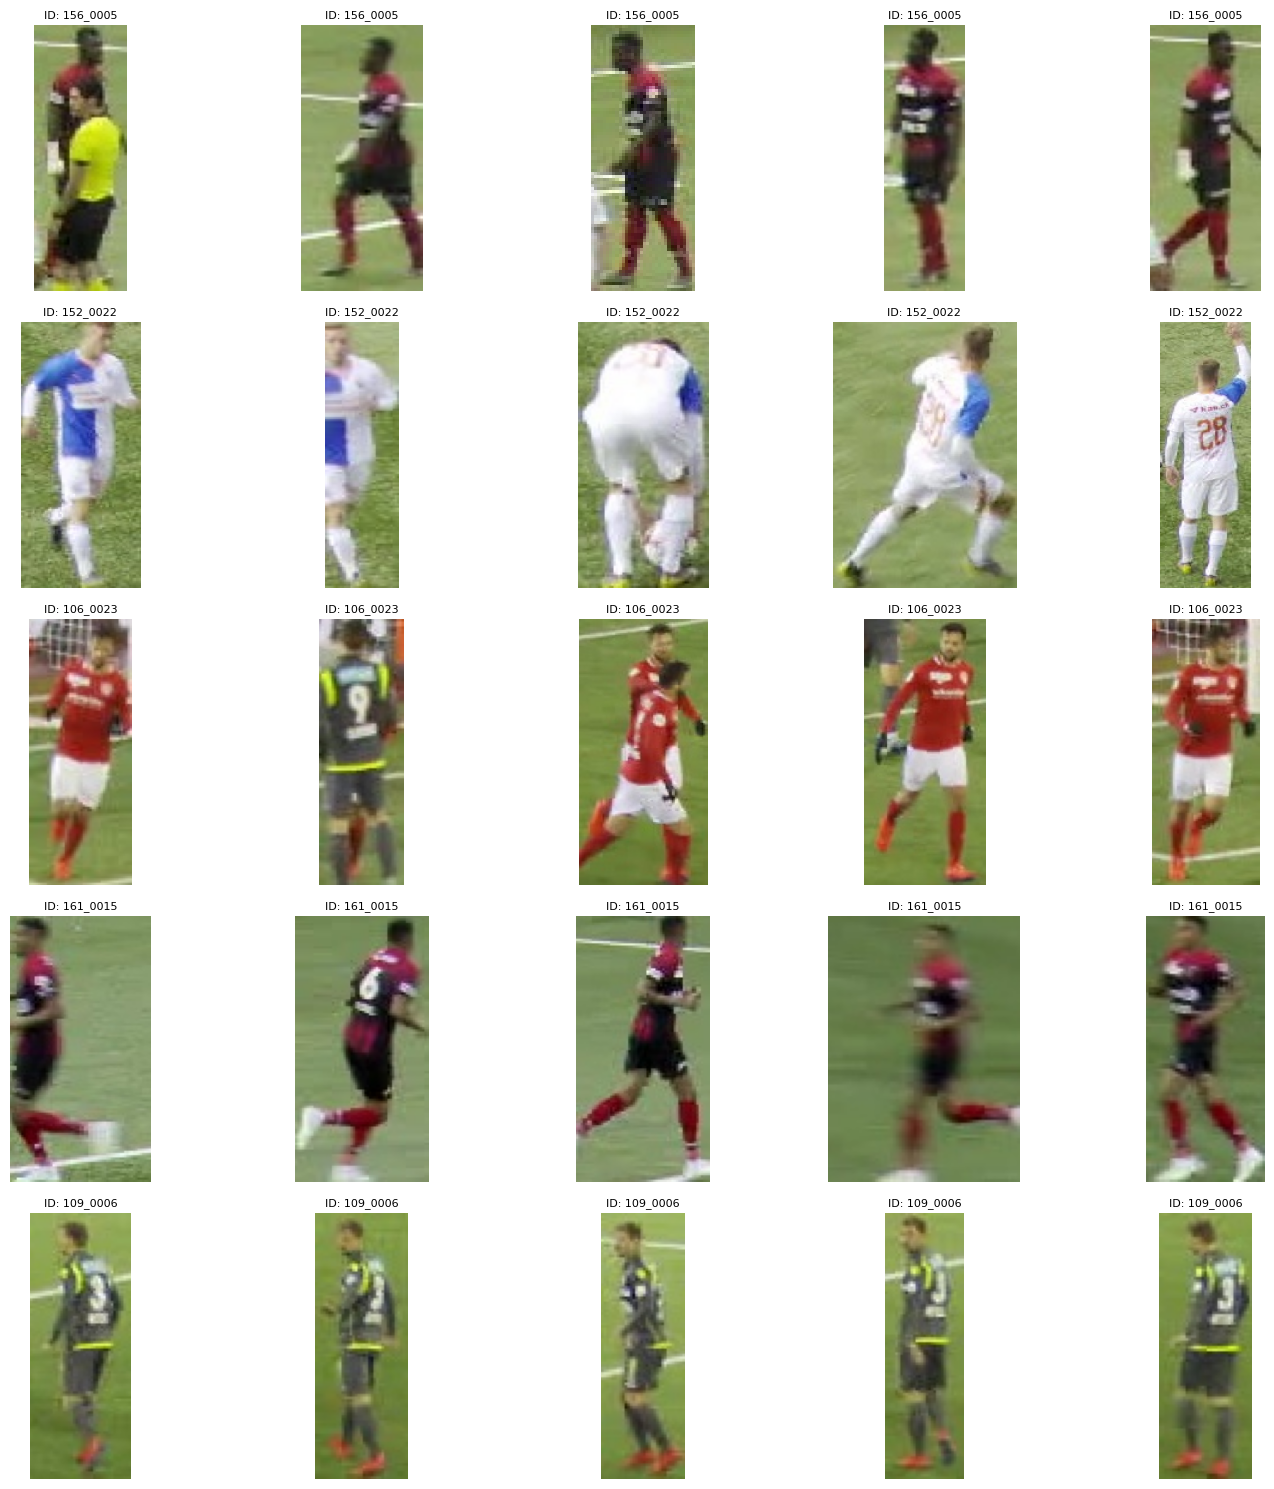

In [ ]:
import os
import cv2
import csv
import glob
import shutil
import random
import configparser
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- CONFIGURATION ---
RAW_DATA_ROOT = "/content/temp_data_raw/train"  # Source folder containing training sequences
OUTPUT_ROOT = "/content/reid_dataset_clean"     # Destination folder for the ReID dataset
FRAME_SAMPLING_INTERVAL = 10                    # Sample 1 frame every N to avoid identical duplicates
MIN_BBOX_AREA = 1000                            # Ignore bounding boxes smaller than this area
VAL_RATIO = 0.15                                # Percentage of sequences used for validation (Query/Gallery)

def ensure_directory_exists(path):
    os.makedirs(path, exist_ok=True)

def get_ignored_ids(ini_path):
    """
    Parses gameinfo.ini to identify track IDs corresponding to the ball.
    Returns a set of IDs to be excluded.
    """
    ignored = set()
    if not os.path.exists(ini_path):
        return ignored

    config = configparser.ConfigParser()
    try:
        config.read(ini_path)
        if 'Sequence' in config:
            for key in config['Sequence']:
                if key.lower().startswith('trackletid_'):
                    val = config['Sequence'][key]
                    # If the object is labeled as 'ball', add ID to the blocklist
                    if 'ball' in val.lower():
                        try:
                            tid = int(key.split('_')[1])
                            ignored.add(tid)
                        except:
                            pass
    except:
        pass
    return ignored

def process_sequence(seq_path, output_base, split_name):
    """
    Processes a single video sequence: reads GT, crops images, and saves them.
    """
    seq_name = os.path.basename(seq_path)
    img_dir = os.path.join(seq_path, "img1")
    gt_path = os.path.join(seq_path, "gt", "gt.txt")
    ini_path = os.path.join(seq_path, "gameinfo.ini")

    if not os.path.exists(gt_path):
        return 0

    # Identify IDs to ignore (e.g., ball)
    ignored_ids = get_ignored_ids(ini_path)

    # Read Ground Truth Data
    gt_data = {} # Dictionary: frame_id -> list of (track_id, x, y, w, h)
    with open(gt_path, 'r') as f:
        reader = csv.reader(f)
        for row in reader:
            try:
                fid = int(row[0])
                tid = int(row[1])

                # Filter: Ignore ball or skipped frames
                if tid in ignored_ids or fid % FRAME_SAMPLING_INTERVAL != 0:
                    continue

                # Filter: Check valid classes (Assuming class 1 = Person/Pedestrian)
                cls = int(row[7]) if len(row) > 7 else 1
                if cls not in [1, -1]:
                    continue

                x, y, w, h = map(float, row[2:6])
                if fid not in gt_data:
                    gt_data[fid] = []
                gt_data[fid].append((tid, x, y, w, h))
            except:
                continue

    # Extract Crops
    count = 0
    frames = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))

    for fpath in frames:
        try:
            fid = int(os.path.basename(fpath).split('.')[0])
        except:
            continue

        if fid not in gt_data:
            continue

        img = cv2.imread(fpath)
        if img is None:
            continue
        H, W, _ = img.shape

        for tid, x, y, w, h in gt_data[fid]:
            # Geometric Filters
            if w * h < MIN_BBOX_AREA: continue # Too small
            if w > h * 1.2: continue           # Aspect ratio check (too wide to be a standing person)

            x1, y1 = max(0, int(x)), max(0, int(y))
            x2, y2 = min(W, int(x+w)), min(H, int(y+h))

            crop = img[y1:y2, x1:x2]
            if crop.size == 0: continue

            # Save Crop
            # Global Unique ID = SequenceName_LocalID
            global_id = f"{seq_name}_{tid:04d}"
            save_dir = os.path.join(output_base, global_id)
            ensure_directory_exists(save_dir)

            out_name = f"{global_id}_f{fid:06d}.jpg"
            cv2.imwrite(os.path.join(save_dir, out_name), crop)
            count += 1

    return count

def visualize_dataset(dataset_root, num_ids=5, num_imgs_per_id=5):
    """
    Visualizes a grid of random samples from the created dataset.
    """
    train_dir = os.path.join(dataset_root, "train")
    if not os.path.exists(train_dir):
        print("Visualization skipped: Train directory not found.")
        return

    # Get all identity folders
    all_ids = sorted(os.listdir(train_dir))
    if not all_ids:
        print("Visualization skipped: No identities found.")
        return

    # Select random identities
    selected_ids = random.sample(all_ids, min(len(all_ids), num_ids))

    print(f"\n--- DATASET VISUALIZATION ({num_ids} Random Identities) ---")
    fig, axes = plt.subplots(num_ids, num_imgs_per_id, figsize=(15, 3 * num_ids))

    for i, pid in enumerate(selected_ids):
        pid_path = os.path.join(train_dir, pid)
        images = sorted(glob.glob(os.path.join(pid_path, "*.jpg")))

        # Select random images for this ID
        selected_imgs = random.sample(images, min(len(images), num_imgs_per_id))

        for j in range(num_imgs_per_id):
            ax = axes[i, j] if num_ids > 1 else axes[j]
            if j < len(selected_imgs):
                img = cv2.imread(selected_imgs[j])
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Convert for matplotlib
                ax.imshow(img)
                ax.set_title(f"ID: {pid}", fontsize=8)
            ax.axis('off')

    plt.tight_layout()
    plt.show()

def build_dataset():
    if os.path.exists(OUTPUT_ROOT):
        shutil.rmtree(OUTPUT_ROOT)

    # Locate all sequences
    all_seqs = sorted(glob.glob(os.path.join(RAW_DATA_ROOT, "*")))
    # Filter for numeric folders only
    all_seqs = [s for s in all_seqs if os.path.isdir(s) and os.path.basename(s).isdigit()]

    if not all_seqs:
        print(f"Error: No sequences found in {RAW_DATA_ROOT}")
        return

    # Shuffle and Split
    random.seed(42)
    random.shuffle(all_seqs)
    n_val = int(len(all_seqs) * VAL_RATIO)
    val_seqs = all_seqs[:n_val]
    train_seqs = all_seqs[n_val:]

    print(f"Dataset Split: {len(train_seqs)} Training Sequences, {len(val_seqs)} Validation Sequences")

    # 1. Process TRAINING Set
    print("Processing Training Set...")
    train_out = os.path.join(OUTPUT_ROOT, "train")
    for s in tqdm(train_seqs):
        process_sequence(s, train_out, "train")

    # 2. Process VALIDATION Set (Simulating Query/Gallery)
    print("Processing Validation Set...")
    query_out = os.path.join(OUTPUT_ROOT, "query")
    gallery_out = os.path.join(OUTPUT_ROOT, "gallery")

    for s in tqdm(val_seqs):
        # Save temporarily
        tmp = os.path.join(OUTPUT_ROOT, "tmp_val")
        cnt = process_sequence(s, tmp, "val")

        # Split: 1 random image to Query, the rest to Gallery
        if cnt > 0 and os.path.exists(tmp):
            for pid in os.listdir(tmp):
                src = os.path.join(tmp, pid)
                imgs = os.listdir(src)
                if len(imgs) < 2: continue

                random.shuffle(imgs)

                # Move to Query
                q_dst = os.path.join(query_out, pid)
                ensure_directory_exists(q_dst)
                shutil.move(os.path.join(src, imgs[0]), os.path.join(q_dst, imgs[0]))

                # Move to Gallery
                g_dst = os.path.join(gallery_out, pid)
                ensure_directory_exists(g_dst)
                for img in imgs[1:]:
                    shutil.move(os.path.join(src, img), os.path.join(g_dst, img))
            shutil.rmtree(tmp)

    print(f"Dataset successfully created at {OUTPUT_ROOT}")

    # Trigger Visualization
    visualize_dataset(OUTPUT_ROOT)

# Execute Builder
build_dataset()

# **Re-Identification Model Fine-Tuning (OSNet)**

This cell executes the training pipeline for the Person Re-Identification (ReID) module. We utilize the **OSNet (Omni-Scale Network)** architecture, specifically the `osnet_x1_0` variant, initializing it with ImageNet pretrained weights to leverage robust feature extraction capabilities.

A custom `SoccerNetDataset` class is implemented to parse the specific directory structure of the processed SoccerNet dataset (Train, Query, Gallery). The model is optimized using **Triplet Loss**, which learns to map images of the same identity close to each other in the embedding space while pushing different identities apart. Finally, the fine-tuned model weights are automatically backed up to Google Drive for use in the tracking inference stage.

In [ ]:
# Install Torchreid directly from the source repository and Faiss for efficient search
!pip install git+https://github.com/KaiyangZhou/deep-person-reid.git
!pip install faiss-cpu

import torch
import torchreid
from torchreid import models
from glob import glob
import matplotlib.pyplot as plt
import re
import shutil
import os
from google.colab import drive

# --- 1. TRAINING PARAMETERS CONFIGURATION ---
DATASET_DIR = "/content/reid_dataset_clean"
OUTPUT_DIR = "/content/reid_model_finetuned"
PRETRAINED_WEIGHTS = "osnet_x1_0_imagenet.pt"
EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 0.0003
DRIVE_BACKUP_PATH = "/content/drive/MyDrive/ArtificialVision_Project_G23/SoccerReID_Models"

# 1. Custom Dataset Wrapper Definition
class SoccerNetDataset(torchreid.data.ImageDataset):
    def __init__(self, root='', **kwargs):
        self.root = os.path.abspath(os.path.expanduser(root))
        train_dir = os.path.join(self.root, 'train')
        query_dir = os.path.join(self.root, 'query')
        gallery_dir = os.path.join(self.root, 'gallery')

        # Process Train
        train = self._process_dir(train_dir, relabel=True)
        # Process Query/Gallery (Must share IDs)
        query, gallery = self._process_test(query_dir, gallery_dir)

        super(SoccerNetDataset, self).__init__(train, query, gallery, **kwargs)

    def _process_dir(self, dir_path, relabel=False):
        img_paths = glob(os.path.join(dir_path, '*', '*.jpg'))
        pid_container = set()
        for img_path in img_paths:
            pid = os.path.basename(os.path.dirname(img_path))
            pid_container.add(pid)
        pid2label = {pid: label for label, pid in enumerate(sorted(pid_container))}
        dataset = []
        for img_path in img_paths:
            pid_name = os.path.basename(os.path.dirname(img_path))
            pid = pid2label[pid_name] if relabel else pid_name
            dataset.append((img_path, pid, 0))
        return dataset

    def _process_test(self, query_path, gallery_path):
        q_paths = glob(os.path.join(query_path, '*', '*.jpg'))
        g_paths = glob(os.path.join(gallery_path, '*', '*.jpg'))
        q_pids = {os.path.basename(os.path.dirname(p)) for p in q_paths}
        g_pids = {os.path.basename(os.path.dirname(p)) for p in g_paths}
        all_pids = sorted(list(q_pids | g_pids))
        pid2label = {pid: i for i, pid in enumerate(all_pids)}

        def _build(paths, camid):
            data = []
            for p in paths:
                pid_name = os.path.basename(os.path.dirname(p))
                if pid_name in pid2label:
                    data.append((p, pid2label[pid_name], camid))
            return data
        return _build(q_paths, 0), _build(g_paths, 1)

# --- 2. Register and Load Dataset ---

torchreid.data.register_image_dataset('soccernet_custom', SoccerNetDataset)

datamanager = torchreid.data.ImageDataManager(
    root=DATASET_DIR,
    sources='soccernet_custom',
    targets='soccernet_custom',
    height=256, width=128,
    batch_size_train=BATCH_SIZE,
    batch_size_test=100,
    transforms=['random_flip', 'random_crop']
)

# --- 3. Build Model ---
print("Building Model...")
model = models.build_model(
    name='osnet_x1_0',
    num_classes=datamanager.num_train_pids,
    loss='triplet',
    pretrained=False
)

if os.path.exists(PRETRAINED_WEIGHTS):
    print(f"Loading pretrained weights from {PRETRAINED_WEIGHTS}")
    torchreid.utils.load_pretrained_weights(model, PRETRAINED_WEIGHTS)
else:
    print("WARNING: Pretrained weights not found. Training from scratch.")

model = model.cuda()

# --- 4. Optimizer & Engine ---
optimizer = torchreid.optim.build_optimizer(model, optim='adam', lr=LEARNING_RATE)
scheduler = torchreid.optim.build_lr_scheduler(optimizer, lr_scheduler='single_step', stepsize=10)

engine = torchreid.engine.ImageTripletEngine(
    datamanager, model, optimizer=optimizer, scheduler=scheduler,
    label_smooth=True
)

# --- 5. Run Training ---
print("Starting Training...")
engine.run(
    save_dir=OUTPUT_DIR,
    max_epoch=EPOCHS,
    eval_freq=5,
    print_freq=10,
    test_only=False
)

# --- SAVE TO DRIVE ---
print("--- BACKING UP TO GOOGLE DRIVE ---")
try:
    drive.mount('/content/drive')
    os.makedirs(DRIVE_BACKUP_PATH, exist_ok=True)

    # Define source and destination
    source_model = os.path.join(OUTPUT_DIR, f"model/model.pth.tar-{EPOCHS}")
    dest_model = os.path.join(DRIVE_BACKUP_PATH, f"osnet_soccer_finetuned_ep{EPOCHS}.pth")

    if os.path.exists(source_model):
        shutil.copy(source_model, dest_model)
        print(f"Model successfully saved to: {dest_model}")
    else:
        print(f"Error: Source model not found at {source_model}")

except Exception as e:
    print(f"Backup failed: {e}")

# **Inference Configuration & Tracker Setup**

This cell initializes the global configuration for the tracking inference pipeline. It defines:
1.  **Paths**: Locations for the fine-tuned detector (YOLOv11), the fine-tuned ReID model (OSNet), and the input/output directories.
2.  **Hyperparameters**: Confidence thresholds and IoU settings for the detector.
3.  **Tracker Settings (BoTSORT)**: A configuration dictionary (`tracker_params`) that tunes the tracking algorithm, enabling the use of the ReID module (`with_reid: True`) and setting association thresholds optimized for soccer player tracking.
4.  **Utilities**: Helper functions to parse Region of Interest (ROI) metadata (`load_rois`) and compute spatial logic (e.g., whether a player is inside a specific field zone).

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/ArtificialVision_Project_G23/FOLDER_FOR_EXAM" -d /content/temp_data_raw/

In [7]:
import os
import yaml
import json
import shutil
import numpy as np
from pathlib import Path
from collections import defaultdict

# --- 1. DEPENDENCY CHECK ---
# Ensures BoxMOT is installed for advanced tracking capabilities
try:
    from boxmot import BotSort
except ImportError:
    import os
    os.system('pip install boxmot --quiet')
    from boxmot import BotSort

# --- 2. GLOBAL CONFIGURATION ---

# --- Paths ---
# Path to the fine-tuned YOLOv11l model weights
DETECTOR_MODEL_PATH = "/content/yolov11l_finetuned_best.pt"

# Path to the fine-tuned ReID Osmet x1.0 model weights
# This file must exist in the current working directory
REID_MODEL_PATH = "/content/osnet_x1_0_finetuned_best.pt"

# Dataset and Output paths
TEST_DATA_PATH = "/content/temp_data_raw/FOLDER_FOR_EXAM"
OUTPUT_DIR = "/content/inference_results_test"
DRIVE_BACKUP_DIR = "/content/drive/MyDrive/ArtificialVision_Project_G23/inference_backup_test"
TRACKER_CONFIG_PATH = "botsort_soccer_tracker.yaml"
TEAM_ID = "23"

# --- Inference Hyperparameters ---
CONF_THRESHOLD = 0.25  # Confidence threshold for YOLO detections
IOU_THRESHOLD = 0.7    # NMS IoU threshold
IMG_SIZE = 1920        # Input image size

# --- Tracker Configuration (BoTSORT) ---
# NOTE: this dictionary is only dumped to YAML for reference. The BotSort constructor in the
# inference cell receives a subset of these values: 'cmc_method', 'fuse_first_associate',
# 'gmc_method', 'fuse_scores' and 'model' are NOT applied, so BoxMOT defaults are used
# (ECC camera-motion compensation, fuse_first_associate=False). See src/tracker.py.
# Defines the internal logic of the tracking algorithm.
tracker_params = {
    'frame_rate': 25,               # Video FPS (standard for TV broadcast soccer)
    'track_buffer': 250,            # History size: keeps lost tracks for 10 seconds (250 frames) to handle long occlusions

    # Association Thresholds (tuned for high-precision ReID)
    'match_thresh': 0.95,           # Strict threshold for matching detections to tracks (0.95 = very strict)
    'appearance_thresh': 0.90,      # ReID similarity threshold: relies heavily on visual features
    'proximity_thresh': 0.70,       # IoU threshold for spatial matching when ReID is uncertain

    # Detection/Tracking Thresholds (Hysteresis Tracking)
    'track_high_thresh': 0.40,      # Threshold to start a NEW track (High confidence only)
    'track_low_thresh': 0.10,       # Threshold to maintain an EXISTING track (keeps tracking even if blurred/occluded)
    'new_track_thresh': 0.15,       # Minimum confidence to confirm a new track initiation

    # Advanced Options
    'fuse_scores': True,            # Multiply detection score with association score for better ranking
    'gmc_method': 'sparseOptFlow',  # Global Motion Compensation: corrects camera movement (essential for soccer pans)
    'with_reid': True,              # Activates the Deep ReID module (OSNet)
    'model': 'auto',                # Automatically selects the model format
    'cmc_method': 'sof',            # Sparse Optical Flow for camera motion compensation
    'fuse_first_associate': True    # Uses ReID features during the first association stage
}

# Generate the YAML configuration file required by BoxMOT
try:
    with open(TRACKER_CONFIG_PATH, 'w') as f:
        yaml.dump(tracker_params, f)
    print(f"[Config] Tracker configuration saved to {TRACKER_CONFIG_PATH}")
except Exception as e:
    print(f"[Error] Failed to save tracker config: {e}")

# --- 2. HELPER FUNCTIONS (ROI & UTILS) ---

def load_rois(roi_json_path):
    """
    Parses the ROI JSON file associated with a video sequence.
    Returns a dictionary of ROIs or None if file is missing.
    """
    if not os.path.exists(roi_json_path):
        return None
    with open(roi_json_path, 'r') as f:
        return json.load(f)

def is_point_in_roi(x, y, roi, img_w, img_h):
    """
    Checks if a specific point (x, y) lies within a normalized ROI.

    Args:
        x, y: Point coordinates in pixels.
        roi: Dictionary containing normalized ROI coordinates (x, y, width, height).
        img_w, img_h: Dimensions of the image.
    Returns:
        bool: True if inside, False otherwise.
    """
    rx = roi['x'] * img_w
    ry = roi['y'] * img_h
    rw = roi['width'] * img_w
    rh = roi['height'] * img_h
    return (rx <= x <= rx + rw) and (ry <= y <= ry + rh)

def get_base_center(x_tl, y_tl, w, h):
    """
    Calculates the center of the bounding box base (bottom-center).
    This is used to determine the player's position relative to the field/ROI.
    """
    cx = x_tl + (w / 2.0)
    cy = y_tl + h
    return cx, cy

def backup_results(source, dest):
    """
    Synchronizes the local output folder to Google Drive for backup.
    """
    print(f"\n[Backup] Syncing results to Drive: {dest} ...")
    try:
        if os.path.exists(dest):
            shutil.rmtree(dest)
        shutil.copytree(source, dest)
        print("[Backup] Backup completed successfully.")
    except Exception as e:
        print(f"[Backup] Backup failed: {e}")

# **Tracking Inference Pipeline**

This cell executes the core inference loop. It integrates the fine-tuned **YOLO detector** and the **BoTSORT tracker** (enhanced with our fine-tuned **OSNet ReID** model) to process the test video sequences.

For each video, the pipeline performs the following operations:
1.  **Detection**: Extracts bounding boxes for players using YOLOv11.
2.  **Tracking**: Associates detections across frames using BoTSORT, leveraging both motion cues (Sparse Optical Flow) and visual appearance (ReID embeddings) to maintain consistent identities even during occlusions.
3.  **Behavior Analysis**: Counts the number of players within specific Regions of Interest (ROIs) for every frame.
4.  **Serialization**: Saves the tracking trajectories and behavior counts to text files formatted for the subsequent evaluation step.

In [8]:
!pip install ultralytics

import os
import torch
import numpy as np
from time import time
from ultralytics import YOLO
from pathlib import Path

# --- 1. MAIN EXECUTION PIPELINE ---

def run_inference_and_generation():
    """
    Executes the full inference pipeline:
    1. Loads the YOLO finetuned model.
    2. Iterates over test video sequences.
    3. Performs tracking using BoxMOT (BoTSORT + Finetuned ReID).
    4. Computes behavior metrics (ROI counting).
    5. Saves results to text files.
    """

    print(f"[Info] Starting Inference Pipeline")
    print(f"       -> Detector: {DETECTOR_MODEL_PATH}")
    print(f"       -> ReID Weights: {REID_MODEL_PATH}")

    # 1. Load the Detection Model
    try:
        model = YOLO(DETECTOR_MODEL_PATH)
    except Exception as e:
        print(f"[Error] Failed to load YOLO model: {e}")
        return

    # Create output directory
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    # 2. Identify Video Sequences
    # Filter for numeric folders only (e.g., '01', '02')
    video_folders = sorted([
        f for f in os.listdir(TEST_DATA_PATH)
        if os.path.isdir(os.path.join(TEST_DATA_PATH, f)) and f.isdigit()
    ], key=lambda x: int(x))

    if not video_folders:
        print(f"[Error] No valid video folders found in {TEST_DATA_PATH}")
        return

    print(f"[Info] Found {len(video_folders)} videos to process.")

    # 3. Processing Loop
    for vid_id in video_folders:
        video_dir = os.path.join(TEST_DATA_PATH, vid_id)
        img_dir = os.path.join(video_dir, "img1")
        roi_path = os.path.join(video_dir, "roi.json")

        # Define output file paths
        track_file = os.path.join(OUTPUT_DIR, f"tracking_{vid_id}_{TEAM_ID}.txt")
        behav_file = os.path.join(OUTPUT_DIR, f"behavior_{vid_id}_{TEAM_ID}.txt")

        # Load ROIs for behavior analysis
        rois = load_rois(roi_path)

        print(f" -> Processing Video {vid_id}...", end='\r')

        # Initialize BoxMOT Tracker
        # We re-initialize for every video to reset the ID counter and buffer
        tracker = BotSort(
            reid_weights=Path(REID_MODEL_PATH),   # Direct path to finetuned weights
            device='0',                           # GPU device
            half=True,                            # FP16 optimization
            det_thresh=CONF_THRESHOLD,
            track_high_thresh=tracker_params['track_high_thresh'],
            track_low_thresh=tracker_params['track_low_thresh'],
            new_track_thresh=tracker_params['new_track_thresh'],
            track_buffer=tracker_params['track_buffer'],
            match_thresh=tracker_params['match_thresh'],
            proximity_thresh=tracker_params['proximity_thresh'],
            appearance_thresh=tracker_params['appearance_thresh'],
            gmc_method=tracker_params['gmc_method'],
            frame_rate=tracker_params['frame_rate'],
            with_reid=tracker_params['with_reid']
        )

        # Open output files
        with open(track_file, 'w') as f_track, open(behav_file, 'w') as f_behav:

            # Run YOLO inference in stream mode for memory efficiency
            results = model.predict(
                source=img_dir,
                conf=CONF_THRESHOLD,
                iou=IOU_THRESHOLD,
                imgsz=IMG_SIZE,
                stream=True,
                verbose=False,
                classes=[0]  # Filter: Person class only
            )

            # Iterate through each frame
            for result in results:
                # Extract frame ID from filename
                frame_name = os.path.basename(result.path)
                frame_id = int(os.path.splitext(frame_name)[0])
                h_img, w_img = result.orig_shape

                # Prepare detections for the tracker
                dets = result.boxes.data.cpu().numpy()
                if len(dets) == 0:
                    dets = np.empty((0, 6))

                # Update Tracker with new detections
                # Returns: [x1, y1, x2, y2, id, conf, cls, ind]
                tracks = tracker.update(dets, result.orig_img)

                # Initialize ROI counters for the current frame
                roi_counts = {1: 0, 2: 0}

                # Process each tracked object
                for track in tracks:
                    x1, y1, x2, y2 = track[:4]
                    track_id = int(track[4])

                    # Calculate width and height
                    w = x2 - x1
                    h = y2 - y1

                    # A. Write Tracking Data
                    # Format: <frame>, <id>, <bb_left>, <bb_top>, <bb_width>, <bb_height>
                    f_track.write(f"{frame_id},{track_id},{x1:.2f},{y1:.2f},{w:.2f},{h:.2f}\n")

                    # B. Behavior Logic (ROI Counting)
                    if rois:
                        # Get player position (bottom-center)
                        cx, cy = get_base_center(x1, y1, w, h)

                        # Check ROI 1
                        if "roi1" in rois and is_point_in_roi(cx, cy, rois["roi1"], w_img, h_img):
                            roi_counts[1] += 1

                        # Check ROI 2
                        if "roi2" in rois and is_point_in_roi(cx, cy, rois["roi2"], w_img, h_img):
                            roi_counts[2] += 1

                # Write Behavior Data (Once per frame)
                # Format: <frame>, <roi_id>, <count>
                f_behav.write(f"{frame_id},1,{roi_counts[1]}\n")
                f_behav.write(f"{frame_id},2,{roi_counts[2]}\n")

    print(f"\n[Success] Inference complete. Results saved locally in {OUTPUT_DIR}")

    # Trigger Backup
    backup_results(OUTPUT_DIR, DRIVE_BACKUP_DIR)

if __name__ == "__main__":
    run_inference_and_generation()

# **Trajectory Post-Processing**

This cell implements the final refinement stage of our tracking pipeline. The `SoccerTrackCleaner` class applies a series of post-processing algorithms designed to correct common tracking errors and ensure data consistency.

The pipeline executes four key operations in sequence:
1.  **Track Stitching**: Reconnects fragmented trajectories caused by temporary occlusions or detector misses. It uses a spatial-temporal heuristic (gap duration and displacement distance) to merge IDs that likely belong to the same player.
2.  **Linear Interpolation**: Fills in short gaps in detection sequences to produce continuous tracks, preventing "flickering" or ghosting.
3.  **Trajectory Smoothing**: Applies a **Savitzky-Golay filter** to the bounding box coordinates. This removes high-frequency noise (jitter) inherent in frame-by-frame detection while preserving the player's true motion dynamics (e.g., accelerations).
4.  **Noise Filtering (Cleanup)**: Discards short tracklets that are statistically likely to be false positives.

Finally, the module ensures strict adherence to the submission format (6 columns: Frame, ID, X, Y, W, H) and enforces integer/float precision standards.

In [9]:
import os
import glob
import shutil
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.signal import savgol_filter
from tqdm import tqdm

class SoccerTrackCleaner:
    """
    A comprehensive post-processing module for Offline Multi-Object Tracking (MOT) in soccer.

    This class implements standard trajectory refinement techniques:
    1. Track Stitching: Recovers IDs after occlusions based on spatial-temporal consistency.
    2. Linear Interpolation: Fills missing detections in short temporal gaps.
    3. Trajectory Smoothing: Applies Savitzky-Golay filter to reduce localization noise.
    4. Noise Filtering: Removes short tracklets (false positives).

    Output Format: 6 Columns (Frame, ID, X, Y, W, H) with standard precision.
    """

    def __init__(self,
                 input_dir,
                 output_dir,
                 img_size=(1920, 1080),
                 do_stitching=True,
                 max_stitch_gap=150,
                 max_stitch_dist=800,
                 border_margin=50,
                 do_interpolation=True,
                 max_interp_gap=20,
                 do_smoothing=True,
                 smooth_window=15,
                 smooth_poly=2,
                 do_cleanup=True,
                 min_track_len=50
                 ):
        """
        Initializes the SoccerTrackCleaner.
        """
        self.input_dir = input_dir
        self.output_dir = output_dir
        self.W, self.H = img_size

        # Configuration
        self.do_stitching = do_stitching
        self.max_stitch_gap = max_stitch_gap
        self.max_stitch_dist = max_stitch_dist
        self.border_margin = border_margin

        self.do_interpolation = do_interpolation
        self.max_interp_gap = max_interp_gap

        self.do_smoothing = do_smoothing
        self.smooth_window = smooth_window
        self.smooth_poly = smooth_poly

        self.do_cleanup = do_cleanup
        self.min_track_len = min_track_len

        # Internal column mapping (Standard MOT)
        self.internal_cols = ['frame', 'id', 'x', 'y', 'w', 'h', 'conf', 'c1', 'c2', 'c3']
        # Output column mapping (Requested 6 columns)
        self.output_cols = ['frame', 'id', 'x', 'y', 'w', 'h']

    def _load_mot_file(self, filepath):
        """Parses a MOT CSV file, normalizing it to internal DataFrame format."""
        if not os.path.exists(filepath):
            return None
        try:
            df = pd.read_csv(filepath, header=None, sep=',')
            if df.empty:
                return None

            # Normalize input to ensure we have at least the first 6 columns correctly named
            if df.shape[1] == 6:
                df.columns = ['frame', 'id', 'x', 'y', 'w', 'h']
                # Add dummy columns for internal processing
                for c in ['conf', 'c1', 'c2', 'c3']:
                    df[c] = -1 if c != 'conf' else 1.0
            elif df.shape[1] >= 10:
                df = df.iloc[:, :10]
                df.columns = self.internal_cols
            else:
                # Fallback: assume first 6 are correct
                df = df.iloc[:, :6]
                df.columns = ['frame', 'id', 'x', 'y', 'w', 'h']
                for c in ['conf', 'c1', 'c2', 'c3']:
                    df[c] = -1 if c != 'conf' else 1.0

            return df
        except Exception as e:
            print(f"[Error] Failed to load {filepath}: {e}")
            return None

    def _is_border(self, cx, cy):
        """Checks if a point is within the border margin."""
        return (cx < self.border_margin or cx > self.W - self.border_margin or
                cy < self.border_margin or cy > self.H - self.border_margin)

    def _run_stitching(self, df):
        """Merges broken tracks based on spatial-temporal proximity."""
        df = df.sort_values(['frame', 'id'])
        unique_ids = df['id'].unique()

        # Gather track statistics
        tracks = {}
        for tid in unique_ids:
            t = df[df['id'] == tid]
            start_row = t.iloc[0]
            end_row = t.iloc[-1]

            s_cx = start_row['x'] + start_row['w']/2
            s_cy = start_row['y'] + start_row['h']/2
            e_cx = end_row['x'] + end_row['w']/2
            e_cy = end_row['y'] + end_row['h']/2

            tracks[tid] = {
                's_f': start_row['frame'], 'e_f': end_row['frame'],
                's_c': (s_cx, s_cy),       'e_c': (e_cx, e_cy),
                'avg_w': t['w'].mean()
            }

        sorted_tids = sorted(tracks.keys(), key=lambda x: tracks[x]['s_f'])
        id_map = {tid: tid for tid in sorted_tids}

        # Merging loop
        for i in range(len(sorted_tids)):
            curr = sorted_tids[i]
            curr_stats = tracks[curr]

            best_prev = None
            min_dist = float('inf')

            for j in range(i-1, -1, -1):
                prev = sorted_tids[j]
                while prev != id_map[prev]: prev = id_map[prev]
                if prev == curr: continue

                prev_stats = tracks[prev]

                # Constraints
                gap = curr_stats['s_f'] - prev_stats['e_f']
                if gap <= 0 or gap > self.max_stitch_gap: continue

                p_x, p_y = prev_stats['e_c']
                c_x, c_y = curr_stats['s_c']
                dist = np.sqrt((c_x - p_x)**2 + (c_y - p_y)**2)

                should_merge = False

                # Logic A: Short Occlusion
                if gap < 25 and dist < (curr_stats['avg_w'] * 3):
                    should_merge = True

                # Logic B: Border Re-entry
                curr_border = self._is_border(c_x, c_y)
                prev_border = self._is_border(p_x, p_y)
                if curr_border and prev_border and dist < self.max_stitch_dist:
                    should_merge = True

                if should_merge and dist < min_dist:
                    min_dist = dist
                    best_prev = prev

            if best_prev:
                id_map[curr] = best_prev
                tracks[best_prev]['e_f'] = curr_stats['e_f']
                tracks[best_prev]['e_c'] = curr_stats['e_c']

        # Apply mapping
        final_map = {}
        for k in id_map:
            root = k
            while root != id_map[root]: root = id_map[root]
            final_map[k] = root

        df['id'] = df['id'].map(final_map)
        return df

    def _run_interpolation(self, df):
        """Linear interpolation for missing frames."""
        if not self.do_interpolation: return df

        new_rows = []
        for tid, group in df.groupby('id'):
            group = group.sort_values('frame')
            frames = group['frame'].values

            for i in range(len(frames)-1):
                f1, f2 = frames[i], frames[i+1]
                gap = f2 - f1

                if 1 < gap <= self.max_interp_gap:
                    row1 = group.iloc[i]
                    row2 = group.iloc[i+1]

                    for step in range(1, int(gap)):
                        frac = step / gap
                        interp_row = row1.copy()
                        interp_row['frame'] = int(f1 + step)
                        interp_row['x'] = row1['x'] + (row2['x'] - row1['x']) * frac
                        interp_row['y'] = row1['y'] + (row2['y'] - row1['y']) * frac
                        interp_row['w'] = row1['w'] + (row2['w'] - row1['w']) * frac
                        interp_row['h'] = row1['h'] + (row2['h'] - row1['h']) * frac
                        new_rows.append(interp_row)

        if new_rows:
            df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)
            df = df.sort_values(['frame', 'id'])
        return df

    def _run_smoothing(self, df):
        """Savitzky-Golay smoothing."""
        if not self.do_smoothing: return df

        smoothed_groups = []
        for tid, group in df.groupby('id'):
            group = group.sort_values('frame')
            if len(group) < self.smooth_window:
                smoothed_groups.append(group)
                continue
            try:
                group['x'] = savgol_filter(group['x'], self.smooth_window, self.smooth_poly)
                group['y'] = savgol_filter(group['y'], self.smooth_window, self.smooth_poly)
                group['w'] = savgol_filter(group['w'], self.smooth_window, self.smooth_poly)
                group['h'] = savgol_filter(group['h'], self.smooth_window, self.smooth_poly)
            except: pass
            smoothed_groups.append(group)

        if smoothed_groups:
            df = pd.concat(smoothed_groups)
        return df

    def _run_cleanup(self, df):
        """Removes short tracks."""
        if not self.do_cleanup: return df
        counts = df['id'].value_counts()
        valid_ids = counts[counts >= self.min_track_len].index
        return df[df['id'].isin(valid_ids)]

    def process_all_videos(self):
        """Runs the pipeline and saves files in 6-column format with correct data types."""
        os.makedirs(self.output_dir, exist_ok=True)

        # Filter for tracking files only
        track_files = glob.glob(os.path.join(self.input_dir, "tracking_*.txt"))

        print(f"[INFO] Processing {len(track_files)} tracking files...")
        print(f"[INFO] Output Directory: {self.output_dir}")

        for fpath in tqdm(track_files, desc="Optimizing"):
            df = self._load_mot_file(fpath)
            if df is None: continue

            # 1. Stitching
            if self.do_stitching:
                df = self._run_stitching(df)

            # 2. Interpolation
            if self.do_interpolation:
                df = self._run_interpolation(df)

            # 3. Smoothing
            if self.do_smoothing:
                df = self._run_smoothing(df)

            # 4. Cleanup
            if self.do_cleanup:
                df = self._run_cleanup(df)

            # Force Integer for Frame and ID
            df['frame'] = df['frame'].astype(int)
            df['id'] = df['id'].astype(int)

            # Round coordinates to 2 decimals (Standard MOT format)
            df['x'] = df['x'].round(2)
            df['y'] = df['y'].round(2)
            df['w'] = df['w'].round(2)
            df['h'] = df['h'].round(2)

            # Save strictly 6 columns (Frame, ID, X, Y, W, H)
            out_path = os.path.join(self.output_dir, os.path.basename(fpath))
            df[self.output_cols].to_csv(out_path, header=False, index=False)

        # Copy behavior files unchanged
        behav_files = glob.glob(os.path.join(self.input_dir, "behavior_*.txt"))
        for bf in behav_files:
            shutil.copy(bf, os.path.join(self.output_dir, os.path.basename(bf)))

        print(f"[SUCCESS] All files processed and saved locally.")

# **Trajectory Post-Processing Execution**

This cell triggers the final optimization pipeline using the refined hyperparameter set. Based on empirical validation, we employ stricter constraints to maximize precision and minimize ID switches.

**Configuration Details:**
* **Stitching**: Enabled with a temporal gap of 150 frames (6s) and a spatial limit of **200 pixels**. This strict spatial constraint ensures that tracks are only merged if the player's re-entry position is spatially consistent with their exit, reducing false associations.
* **Interpolation**: Restricted to **15 frames (0.6s)**. This conservative gap filling prevents "ghosting" effects during rapid direction changes.
* **Smoothing**: A 15-frame Savitzky-Golay window (Poly=2) is applied to stabilize bounding boxes.
* **Cleanup**: Tracks shorter than **50 frames (2s)** are removed to filter out detector noise.

The processed tracking data and behavior counts are saved to the final output directory, ready for submission.

In [10]:
import os

# --- PATH CONFIGURATION ---
INPUT_RAW_RESULTS = "/content/inference_results_test"      # Input folder
OUTPUT_FINAL_RESULTS = "/content/Predictions_folder"  # Output folder (Local)

# --- HYPERPARAMETERS ---
DO_STITCHING = True
MAX_STITCH_GAP = 150       # Frames (6 seconds at 25fps)
MAX_STITCH_DIST = 200      # Pixels (Stricter spatial limit for border logic)

DO_INTERPOLATION = True
MAX_INTERP_GAP = 15        # Max 0.6 seconds gap

DO_SMOOTHING = True
SMOOTH_WINDOW = 15         # Filter window size (~0.6s)
SMOOTH_POLY = 2            # Polynomial order (Quadratic)

DO_CLEANUP = True
MIN_TRACK_LEN = 50         # Min frames to keep a track (2 seconds)

# --- MAIN EXECUTION ---
if __name__ == "__main__":
    if not os.path.exists(INPUT_RAW_RESULTS):
        print(f"[ERROR] Input folder not found: {INPUT_RAW_RESULTS}")
    else:
        # Initialize Cleaner
        cleaner = SoccerTrackCleaner(
            input_dir=INPUT_RAW_RESULTS,
            output_dir=OUTPUT_FINAL_RESULTS,

            do_stitching=DO_STITCHING,
            max_stitch_gap=MAX_STITCH_GAP,
            max_stitch_dist=MAX_STITCH_DIST,

            do_interpolation=DO_INTERPOLATION,
            max_interp_gap=MAX_INTERP_GAP,

            do_smoothing=DO_SMOOTHING,
            smooth_window=SMOOTH_WINDOW,
            smooth_poly=SMOOTH_POLY,

            do_cleanup=DO_CLEANUP,
            min_track_len=MIN_TRACK_LEN
        )

        # Run Pipeline
        cleaner.process_all_videos()

In [11]:
!zip -r -q /content/Predictions_folder.zip /content/Predictions_folder

# **Official Evaluation Metric Calculation**
This cell computes the final performance metrics for the project using the official SoccerNet evaluation logic. It calculates the **HOTA** score (Higher Order Tracking Accuracy) at a threshold of 0.5 using the TrackEval library and the **nMAE** (Normalized Mean Absolute Error) by comparing the predicted crowd counts against the generated ground truth behavior data. The sum of these two metrics constitutes the final **PTBS** (Performance Total Benchmark Score).

In [ ]:
import os
import shutil
import numpy as np

# --- 1. CONFIGURATION ---

# Must match the split used in the Inference step!
TARGET_SPLIT = "test"

# Path to the Ground Truth Data (where we generated metadata)
GT_DATASET_ROOT = os.path.join("/content/temp_data_raw/test_set", TARGET_SPLIT)

# Directory containing the predictions (from the previous step)
PREDICTIONS_ROOT = f"/content/Predictions_folder"

# Temporary folder for TrackEval internal processing
TEMP_TRACKEVAL_ROOT = "/content/temp_trackeval_workspace"

# Parameters
GROUP_ID = "23"
FPS = 25.0

# --- 2. NUMPY COMPATIBILITY PATCH ---
if not hasattr(np, "float"):
    np.float = float
if not hasattr(np, "int"):
    np.int = int
if not hasattr(np, "bool"):
    np.bool = bool

# --- 3. EVALUATION EXECUTION ---

from evaluation_helper import (
    compute_hota_at_05_trackeval,
    build_trackeval_structure,
    compute_nmae_from_behavior_files
)

def run_evaluation():
    print(f"--- Starting Evaluation for Team {GROUP_ID} on {TARGET_SPLIT.upper()} ---")
    print(f"GT Path: {GT_DATASET_ROOT}")
    print(f"Predictions Path: {PREDICTIONS_ROOT}")

    if not os.path.exists(GT_DATASET_ROOT):
        print(f"[Error] GT Path not found. Did you run metadata generation?")
        return
    if not os.path.exists(PREDICTIONS_ROOT):
        print(f"[Error] Predictions path not found. Did you run inference?")
        return

    # 1. HOTA Calculation
    print("\n[Metric 1/2] Preparing HOTA calculation (TrackEval)...")
    try:
        gt_folder, tr_folder, seqmap_file = build_trackeval_structure(
            dataset_root=GT_DATASET_ROOT,
            predictions_root=PREDICTIONS_ROOT,
            group=GROUP_ID,
            split=TARGET_SPLIT,
            fps=FPS,
            tmp_root=TEMP_TRACKEVAL_ROOT
        )

        hota_score = compute_hota_at_05_trackeval(
            gt_folder=gt_folder,
            trackers_folder=tr_folder,
            seqmap_file=seqmap_file,
            split=TARGET_SPLIT
        )
        print(f">>> HOTA@0.5: {hota_score:.6f}")

    except FileNotFoundError as e:
        print(f"[Error] HOTA calculation stopped: {e}")
        hota_score = 0.0
    except Exception as e:
        print(f"[Error] HOTA calculation failed: {e}")
        hota_score = 0.0

    # 2. nMAE Calculation
    print("\n[Metric 2/2] Computing Behavior Analysis Error (nMAE)...")
    try:
        beh_metrics = compute_nmae_from_behavior_files(
            dataset_root=GT_DATASET_ROOT,
            predictions_root=PREDICTIONS_ROOT,
            group=GROUP_ID
        )

        nmae_score = 0.0
        if beh_metrics['has_behavior']:
            nmae_score = beh_metrics['nMAE']
            print(f">>> MAE: {beh_metrics['MAE']:.4f}")
            print(f">>> nMAE: {nmae_score:.6f}")
        else:
            print("[Warning] Behavior data missing. Cannot compute nMAE.")

    except Exception as e:
        print(f"[Error] nMAE calculation failed: {e}")
        nmae_score = 0.0

    # 3. Final Score
    ptbs = hota_score + nmae_score
    print(f"\n==========================================")
    print(f" FINAL SCORE (PTBS): {ptbs:.6f}")
    print(f" (HOTA: {hota_score:.4f} + nMAE: {nmae_score:.4f})")
    print(f"==========================================")

    # Cleanup
    if os.path.exists(TEMP_TRACKEVAL_ROOT):
        shutil.rmtree(TEMP_TRACKEVAL_ROOT, ignore_errors=True)

if __name__ == "__main__":
    run_evaluation()

In [16]:
!zip -r -q /content/inference_results_postprocessed.zip /content/inference_results_postprocessed

# **Visual Qualitative Analysis (Side-by-Side with Dynamic Coloring)**
This cell generates a comparison video replicating the official visualization style. The bounding boxes change color dynamically based on their position relative to the ROIs, matching the original logic:

**Blue Box:** Object is counted inside ROI 1.

**Red Box:** Object is counted inside ROI 2.

**Green/Yellow Box:** Object is outside any ROI (Green for GT, Yellow for Prediction).

In [ ]:
import os
import cv2
import glob
import json
import pandas as pd
from collections import defaultdict
from tqdm import tqdm
from google.colab import files

# --- 1. CONFIGURATION & VARIABLES ---

# Video ID to visualize
VIDEO_ID = "146"
TEAM_ID = "23"

# Dataset Selection
TARGET_SPLIT = "test"

# Dynamic Paths
GT_DATASET_ROOT = os.path.join("/content/temp_data_raw", TARGET_SPLIT)
PREDICTIONS_DIR = f"/content/inference_results_postprocessed"

# Visualization Settings
OUTPUT_FILENAME = f"comparison_dynamic_video_{VIDEO_ID}.mp4"
FPS = 25.0
MAX_FRAMES = None

# Colors (BGR Format)
COLOR_ROI_1 = (255, 0, 0)             # Blue
COLOR_ROI_2 = (0, 0, 255)             # Red
COLOR_GT_DEFAULT = (0, 255, 255)      # Yellow
COLOR_PRED_DEFAULT = (0, 255, 255)    # Yellow
TEXT_COLOR = (255, 255, 255)          # White

# --- 2. HELPER FUNCTIONS ---
# Drawing helpers (ROI/box rendering) adapted from the course-provided contest simulator.

def read_tracking_file(filepath):
    data = defaultdict(list)
    if not os.path.exists(filepath):
        print(f"[Warning] File not found: {filepath}")
        return data
    try:
        with open(filepath, 'r') as f:
            for line in f:
                parts = line.strip().split(',')
                if len(parts) < 6: continue
                data[int(parts[0])].append((
                    int(parts[1]),
                    int(float(parts[2])),
                    int(float(parts[3])),
                    int(float(parts[4])),
                    int(float(parts[5]))
                ))
    except Exception as e:
        print(f"[Error] Reading file {filepath}: {e}")
    return data

def read_behavior_file(filepath):
    data = defaultdict(dict)
    if not os.path.exists(filepath): return data
    with open(filepath, 'r') as f:
        for line in f:
            parts = line.strip().split(',')
            if len(parts) < 3: continue
            data[int(parts[0])][int(parts[1])] = int(float(parts[2]))
    return data

def roi_pixel_rect(roi_norm, img_w, img_h):
    x1 = int(round(roi_norm["x"] * img_w))
    y1 = int(round(roi_norm["y"] * img_h))
    rw = int(round(roi_norm["width"] * img_w))
    rh = int(round(roi_norm["height"] * img_h))
    return x1, y1, x1 + rw, y1 + rh

def clip_rect(x1, y1, x2, y2, w, h):
    x1 = max(0, min(w - 1, x1))
    y1 = max(0, min(h - 1, y1))
    x2 = max(0, min(w - 1, x2))
    y2 = max(0, min(h - 1, y2))
    return x1, y1, x2, y2

def bbox_base_center(x, y, w, h):
    return int(round(x + w / 2.0)), int(round(y + h))

def point_in_rect(px, py, rect):
    x1, y1, x2, y2 = rect
    return (x1 <= px <= x2) and (y1 <= py <= y2)

def draw_rois(img, rois, roi_colors):
    if not rois: return
    H, W = img.shape[:2]
    for name, r in rois.items():
        x1, y1, x2, y2 = roi_pixel_rect(r, W, H)
        x1, y1, x2, y2 = clip_rect(x1, y1, x2, y2, W, H)
        color = roi_colors.get(name, (0, 255, 0))
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img, name, (x1, max(0, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

def draw_roi_counts(img, rois, roi_colors, counts, roi_ids=(1, 2)):
    if not rois: return
    H, W = img.shape[:2]
    roi_names = sorted(rois.keys())
    for k, roi_name in enumerate(roi_names[:len(roi_ids)]):
        rid = roi_ids[k]
        val = int(counts.get(rid, 0))
        r = rois[roi_name]
        x1, y1, x2, y2 = roi_pixel_rect(r, W, H)
        x1, y1, x2, y2 = clip_rect(x1, y1, x2, y2, W, H)

        # Same text placement as the official contest simulator
        tx = x1 + 10
        ty = y1 + 70
        color = roi_colors.get(roi_name, (255, 255, 255))

        cv2.putText(img, str(val), (tx, ty),
                    cv2.FONT_HERSHEY_SIMPLEX, 2.5, color, 6, cv2.LINE_AA)

def draw_boxes_roi_colored(img, items, rois, roi_colors, out_color, draw_ids=True):
    H, W = img.shape[:2]

    # Pre-calculate ROI rects if they exist
    roi_rects = []
    if rois:
        roi_rects = [(name, roi_pixel_rect(r, W, H)) for name, r in rois.items()]

    for (obj_id, x, y, bw, bh) in items:
        cx, cy = bbox_base_center(x, y, bw, bh)

        roi_name = None
        for name, rect in roi_rects:
            if point_in_rect(cx, cy, rect):
                roi_name = name
                break

        color = roi_colors.get(roi_name, out_color) if roi_name else out_color

        x1, y1, x2, y2 = clip_rect(x, y, x + bw, y + bh, W, H)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        cv2.circle(img, (max(0, min(W - 1, cx)), max(0, min(H - 1, cy))), 3, color, -1)

        if draw_ids:
            cv2.putText(img, str(obj_id), (x1, max(0, y1 - 6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

# --- 3. MAIN GENERATOR ---

def generate_dynamic_comparison():
    print(f"--- Generating Exact Video for {VIDEO_ID} ---")

    # Paths
    vid_root = os.path.join(GT_DATASET_ROOT, VIDEO_ID)
    img_dir = os.path.join(vid_root, "img1")
    roi_path = os.path.join(vid_root, "roi.json")

    gt_track = os.path.join(vid_root, "gt", "gt.txt")
    gt_behav = os.path.join(vid_root, "gt", "behavior_gt.txt")
    pred_track = os.path.join(PREDICTIONS_DIR, f"tracking_{VIDEO_ID}_{TEAM_ID}.txt")
    pred_behav = os.path.join(PREDICTIONS_DIR, f"behavior_{VIDEO_ID}_{TEAM_ID}.txt")

    if not os.path.exists(pred_track):
        print(f"[Error] Prediction file missing: {pred_track}")
        return

    # Load Data
    gt_data = read_tracking_file(gt_track)
    pred_data = read_tracking_file(pred_track)
    gt_counts = read_behavior_file(gt_behav)
    pred_counts = read_behavior_file(pred_behav)

    rois = None
    if os.path.exists(roi_path):
        with open(roi_path, 'r') as f: rois = json.load(f)

    # Setup Colors map
    roi_colors = {}
    if rois:
        r_names = sorted(rois.keys())
        if len(r_names) >= 1: roi_colors[r_names[0]] = COLOR_ROI_1
        if len(r_names) >= 2: roi_colors[r_names[1]] = COLOR_ROI_2

    # Setup Video
    frames = sorted(glob.glob(os.path.join(img_dir, "*.jpg")))
    if not frames: return

    first_im = cv2.imread(frames[0])
    h, w = first_im.shape[:2]
    out = cv2.VideoWriter(OUTPUT_FILENAME, cv2.VideoWriter_fourcc(*'mp4v'), FPS, (w*2, h))

    limit = min(len(frames), MAX_FRAMES) if MAX_FRAMES else len(frames)

    for i in tqdm(range(limit)):
        frame_id = i + 1
        img_left = cv2.imread(frames[i])
        img_right = img_left.copy()

        # --- LEFT (GT) ---
        # 1. Counts Bottom-Left
        total_gt = sum(gt_counts.get(frame_id, {}).values())
        cv2.putText(img_left, f"TOTAL: {total_gt}", (10, h-20),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255,255,255), 2, cv2.LINE_AA)

        # 2. ROIs & Boxes
        draw_rois(img_left, rois, roi_colors)
        draw_roi_counts(img_left, rois, roi_colors, gt_counts.get(frame_id, {}))
        draw_boxes_roi_colored(img_left, gt_data.get(frame_id, []), rois, roi_colors, COLOR_GT_DEFAULT)

        # 3. Header Info
        header_text = f"GT | video {VIDEO_ID} | {TEAM_ID} | frame {frame_id}/{len(frames)}"
        cv2.putText(img_left, header_text, (10, 30),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)

        # --- RIGHT (PRED) ---
        # 1. Counts Bottom-Left
        total_pred = sum(pred_counts.get(frame_id, {}).values())
        cv2.putText(img_right, f"TOTAL: {total_pred}", (10, h-20),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255,255,255), 2, cv2.LINE_AA)

        # 2. ROIs & Boxes
        draw_rois(img_right, rois, roi_colors)
        draw_roi_counts(img_right, rois, roi_colors, pred_counts.get(frame_id, {}))
        draw_boxes_roi_colored(img_right, pred_data.get(frame_id, []), rois, roi_colors, COLOR_PRED_DEFAULT)

        # 3. Header Info
        header_text_pred = f"PRED | video {VIDEO_ID} | {TEAM_ID} | frame {frame_id}/{len(frames)}"
        cv2.putText(img_right, header_text_pred, (10, 30),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)

        # Combine
        combined = cv2.hconcat([img_left, img_right])
        # Vertical Separator Line
        cv2.line(combined, (w, 0), (w, h), (255, 255, 255), 2)

        out.write(combined)

    out.release()
    print(f"\n[Success] Saved: {OUTPUT_FILENAME}")
    try: files.download(OUTPUT_FILENAME)
    except: pass

if __name__ == "__main__":
    generate_dynamic_comparison()